# Modelado y Benchmarking de Clasificación

### Imports y Carga de Datos

In [1]:
import sys
sys.path.append("/workspace/src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

from Modelado import (
    SEED, PREDICTORES, TARGET, COLUMNAS_EXCLUIDAS, MODELO_REFERENCIA, NOMBRES_MODELOS, UMBRAL,
    separar_x_y, dividir_train_test, crear_preprocesador, definir_modelos, ajustar_modelos,
    coeficientes_logistica, evaluar_cv, formatear_tabla_cv, evaluar_test,
    graficar_curvas_roc_pr, graficar_matrices_confusion,
    guardar_modelos, guardar_metricas, guardar_split, guardar_metadatos, cargar_modelo,
)

In [2]:
SEED  # 42, definido en src/Modelado.py y usado en el split, el CV, el tuning y los modelos

42

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')
df.shape

(4810, 10)

### Selección de Predictores

Se usan los 6 predictores del modelado. Las columnas excluidas y los motivos se explican en [Datos, predictores y split](#mod-datos).

In [4]:
print("Columnas excluidas:", COLUMNAS_EXCLUIDAS)
print("Predictores:", PREDICTORES)
print("Target:", TARGET)

Columnas excluidas: ['subject_id', 'bdi_total', 'depressed', 'est_leisure_screen_hours']
Predictores: ['sleep_quality_index', 'avg_sleep_hours', 'midsleep_weekend_hours', 'social_jetlag_hours', 'screen_time_index', 'sex']
Target: depressed


### División Train/Test

Se separa un 20% de los datos como test, estratificado por sexo × depresión ([Datos, predictores y split](#mod-datos)). Este notebook crea el split (`split_indices.csv`) que reutilizan todos los demás.

In [5]:
df_train, df_test = dividir_train_test(df, test_size=0.2, seed=SEED)

X_train, y_train = separar_x_y(df_train)
X_test, y_test = separar_x_y(df_test)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")

Train: (3848, 6)  |  Test: (962, 6)


In [6]:
# Proporción de cada combinación sexo × depresión en ambos conjuntos
proporciones = pd.DataFrame({
    "Train (%)": df_train.groupby(["sex", TARGET]).size() / len(df_train) * 100,
    "Test (%)": df_test.groupby(["sex", TARGET]).size() / len(df_test) * 100,
}).round(2)
proporciones.index.names = ["Sexo", "Deprimido"]
proporciones

Train (%)  Test (%)
Sexo Deprimido                     
Boy  0              46.49     46.47
     1               4.37      4.37
Girl 0              37.14     37.21
     1              12.01     11.95

Las cuatro combinaciones mantienen prácticamente la misma proporción en train y test, de modo que ambos conjuntos son comparables.

### Preprocesamiento

`StandardScaler` en las numéricas y `OneHotEncoder(drop="first")` en `sex`, dentro de un `Pipeline` con cada modelo ([Datos, predictores y split](#mod-datos)).

In [7]:
crear_preprocesador()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

### Modelos y Espacios de Búsqueda

Todos los modelos compensan el desbalance de clases (16.4% de positivos) con pesos:

| Clave | Modelo | Manejo del desbalance | Tuning |
|---|---|---|---|
| `logistica_benchmark` | Regresión logística (**referencia**) | `class_weight="balanced"` | No |
| `logistica_ridge` | Logística con penalización L2 | `class_weight="balanced"` | `C` |
| `logistica_lasso` | Logística con penalización L1 (`liblinear`) | `class_weight="balanced"` | `C` |
| `random_forest` | Random Forest | `class_weight="balanced_subsample"` | Sí |
| `xgboost` | XGBoost | `scale_pos_weight = n_neg / n_pos` del train | Sí |
| `lightgbm` | LightGBM | `class_weight="balanced"` | Sí |
| `catboost` | CatBoost | `auto_class_weights="Balanced"` | Sí |

La logística benchmark es el modelo de referencia ([Comparación final y test](#mod-comparacion)).

In [8]:
n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = n_neg / n_pos
print(f"Negativos: {n_neg}  |  Positivos: {n_pos}  |  scale_pos_weight = {scale_pos_weight:.3f}")

modelos = definir_modelos(scale_pos_weight, seed=SEED)

Negativos: 3218  |  Positivos: 630  |  scale_pos_weight = 5.108


### Tuning de Hiperparámetros

Se usa `RandomizedSearchCV` **solo sobre el train** con `StratifiedKFold(5, shuffle=True)` y `scoring="average_precision"` (PR-AUC). Se prueban 40 combinaciones por modelo de árboles y 10 valores de `C` para las logísticas regularizadas (`C` log-uniforme entre 1e-3 y 1e2). Con `refit=True`, al terminar cada búsqueda el mejor Pipeline queda **reentrenado con todo el train**. La logística benchmark se entrena directamente, sin búsqueda.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

pipelines, mejores_hiperparametros = ajustar_modelos(modelos, X_train, y_train, cv, seed=SEED)

✓ Logística benchmark


✓ Logística Ridge (L2)
✓ Logística Lasso (L1)


✓ Random Forest


✓ XGBoost


✓ LightGBM


✓ CatBoost


In [10]:
# Mejores hiperparámetros encontrados (el benchmark no tiene tuning)
for clave, params in mejores_hiperparametros.items():
    texto = ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items())
    print(f"{NOMBRES_MODELOS[clave]:<22} {texto or 'sin tuning'}")

Logística benchmark    sin tuning
Logística Ridge (L2)   C=0.9847
Logística Lasso (L1)   C=0.07459
Random Forest          max_depth=5, max_features=0.5, min_samples_leaf=10, n_estimators=585
XGBoost                colsample_bytree=0.7297, learning_rate=0.01442, max_depth=2, min_child_weight=7, n_estimators=289, subsample=0.644
LightGBM               colsample_bytree=0.9443, learning_rate=0.01021, max_depth=7, min_child_samples=36, n_estimators=236, num_leaves=8, subsample=0.877
CatBoost               depth=3, iterations=543, l2_leaf_reg=4.554, learning_rate=0.02409


La búsqueda favoreció modelos simples: árboles poco profundos (XGBoost con `max_depth=2`, CatBoost con `depth=3`, Random Forest con `max_depth=5`) y tasas de aprendizaje bajas. Para la Ridge, el mejor `C` (≈0.98) es prácticamente el valor por defecto (`C=1`), y como `LogisticRegression` usa penalización L2 por defecto, **la Ridge resulta casi idéntica a la logística benchmark**. Con 3,848 observaciones y solo 6 predictores hay poco sobreajuste que corregir con regularización.

**Coeficientes de las logísticas**

La penalización L1 (Lasso) puede llevar coeficientes exactamente a cero, lo que equivale a una selección de variables. Se comparan los coeficientes (sobre variables estandarizadas) del benchmark y de la Lasso.

In [11]:
coef_benchmark = coeficientes_logistica(pipelines["logistica_benchmark"])
coef_lasso = coeficientes_logistica(pipelines["logistica_lasso"])

tabla_coeficientes = pd.DataFrame({
    "Benchmark": coef_benchmark.set_index("Variable")["Coeficiente"],
    "Lasso": coef_lasso.set_index("Variable")["Coeficiente"],
    "Lasso en cero": coef_lasso.set_index("Variable")["En cero"],
}).round(3)
tabla_coeficientes

,Benchmark,Lasso,Lasso en cero
Variable,,,
sleep_quality_index,0.572,0.558,False
avg_sleep_hours,-0.181,-0.204,False
midsleep_weekend_hours,0.242,0.144,False
social_jetlag_hours,-0.076,0.000,True
screen_time_index,0.094,0.079,False
sex_Girl,1.091,0.971,False


In [12]:
en_cero = coef_lasso.loc[coef_lasso["En cero"], "Variable"].tolist()
print("Coeficientes de la Lasso en cero:", en_cero if en_cero else "ninguno")

Coeficientes de la Lasso en cero: ['social_jetlag_hours']


La Lasso (con `C` ≈ 0.075, una regularización fuerte) lleva a cero únicamente el coeficiente de `social_jetlag_hours`. Es coherente con el EDA: el jetlag social está muy correlacionado con `midsleep_weekend_hours` (r = 0.84) y era el dominio del sueño con la asociación más débil con el BDI-II, así que su información ya está contenida en el cronotipo. El resto de coeficientes se encogen ligeramente pero conservan el signo y el orden de importancia: `sex_Girl` y `sleep_quality_index` son, por lejos, los predictores con más peso.

### Benchmarking: Validación Cruzada

Cada modelo, con sus mejores hiperparámetros, se evalúa con validación cruzada estratificada de 5 folds en el train (los mismos folds del tuning). Se reporta la media ± desviación estándar de cada métrica; las de clase (precision, recall, F1, accuracy) usan el umbral por defecto de 0.5. La tabla se ordena por PR-AUC y la última columna muestra la diferencia de PR-AUC de cada modelo frente a la logística benchmark.

**Nota:** como los hiperparámetros se eligieron con estos mismos folds, la PR-AUC de CV de los modelos con tuning es ligeramente optimista frente a la del benchmark (que no tiene tuning). Por eso el test, que nunca se usó, es la comparación final.

In [13]:
tabla_cv = evaluar_cv(pipelines, X_train, y_train, cv)
formatear_tabla_cv(tabla_cv)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Δ PR-AUC vs benchmark
Modelo,,,,,,,
CatBoost,0.395 ± 0.022,0.753 ± 0.018,0.307 ± 0.009,0.652 ± 0.020,0.417 ± 0.011,0.701 ± 0.009,0.007
Random Forest,0.392 ± 0.020,0.747 ± 0.020,0.327 ± 0.007,0.589 ± 0.027,0.420 ± 0.008,0.734 ± 0.009,0.004
LightGBM,0.390 ± 0.022,0.750 ± 0.017,0.309 ± 0.008,0.651 ± 0.043,0.419 ± 0.011,0.705 ± 0.013,0.002
Logística Lasso (L1),0.389 ± 0.013,0.755 ± 0.019,0.308 ± 0.011,0.651 ± 0.018,0.418 ± 0.013,0.703 ± 0.011,0.001
XGBoost,0.388 ± 0.026,0.752 ± 0.019,0.305 ± 0.013,0.663 ± 0.033,0.417 ± 0.017,0.697 ± 0.013,0.000
Logística Ridge (L2),0.388 ± 0.015,0.755 ± 0.019,0.306 ± 0.015,0.641 ± 0.025,0.414 ± 0.019,0.702 ± 0.014,0.000
Logística benchmark,0.388 ± 0.015,0.755 ± 0.019,0.306 ± 0.015,0.641 ± 0.025,0.414 ± 0.019,0.702 ± 0.014,0.000


In [14]:
# Mejor modelo según PR-AUC de CV (la tabla ya está ordenada)
clave_por_nombre = {nombre: clave for clave, nombre in NOMBRES_MODELOS.items()}
clave_mejor = clave_por_nombre[tabla_cv.index[0]]
print("Mejor modelo según PR-AUC de CV:", NOMBRES_MODELOS[clave_mejor])

Mejor modelo según PR-AUC de CV: CatBoost


En validación cruzada **CatBoost** obtiene la mayor PR-AUC (0.395 ± 0.022), seguido de Random Forest (0.392) y LightGBM (0.390). La logística benchmark queda en 0.388 ± 0.015, es decir, CatBoost la supera en apenas **+0.007** de PR-AUC (≈ 2% relativo). Todos los modelos están en un rango de 0.388 a 0.395, una diferencia **menor que la desviación estándar entre folds** (0.013–0.026), por lo que en la práctica son indistinguibles. Todos más que duplican la PR-AUC de un clasificador aleatorio (~0.164) y tienen ROC-AUC de ~0.75.

Con el umbral 0.5, el Random Forest es el más conservador (mayor precision y accuracy, menor recall), mientras que el resto ofrece un equilibrio parecido: recall de ~0.65 con precision de ~0.31.

### Benchmarking: Test

Los modelos ya están reentrenados con todo el train (benchmark con `fit` directo y el resto con `refit=True` de la búsqueda). Ahora se evalúan **una única vez** en el test. Las métricas de clase usan el umbral 0.5.

In [15]:
tabla_test = evaluar_test(pipelines, X_test, y_test, umbral=UMBRAL)
tabla_test.round(3)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Δ PR-AUC vs benchmark
Modelo,,,,,,,
Logística Lasso (L1),0.420,0.803,0.338,0.758,0.468,0.718,0.002
Logística Ridge (L2),0.417,0.801,0.335,0.764,0.466,0.714,0.000
Logística benchmark,0.417,0.801,0.335,0.764,0.466,0.714,0.000
XGBoost,0.416,0.798,0.332,0.771,0.464,0.710,-0.001
LightGBM,0.415,0.799,0.329,0.720,0.452,0.715,-0.002
CatBoost,0.414,0.793,0.326,0.745,0.453,0.707,-0.003
Random Forest,0.410,0.793,0.344,0.688,0.459,0.735,-0.007


En el test el orden cambia: la **Logística Lasso** obtiene la mayor PR-AUC (0.420), la benchmark y la Ridge quedan en 0.417, y CatBoost, el mejor en CV, queda ligeramente **por debajo** del benchmark (0.414, −0.003). Que el ranking se invierta entre CV y test confirma que las diferencias son ruido de muestreo y no ventajas reales de un modelo sobre otro. Todos los modelos tienen ROC-AUC de ~0.80 y PR-AUC de 0.41–0.42 en el test, algo mejor que en CV, lo que se explica por la variabilidad de un test de solo 962 adolescentes (157 positivos).

**Curvas ROC y Precision-Recall**

Se superponen las curvas de todos los modelos en el test. La logística benchmark aparece resaltada (línea gruesa en color tinta); las logísticas regularizadas van con línea discontinua y los modelos de árboles con línea continua o punteada.

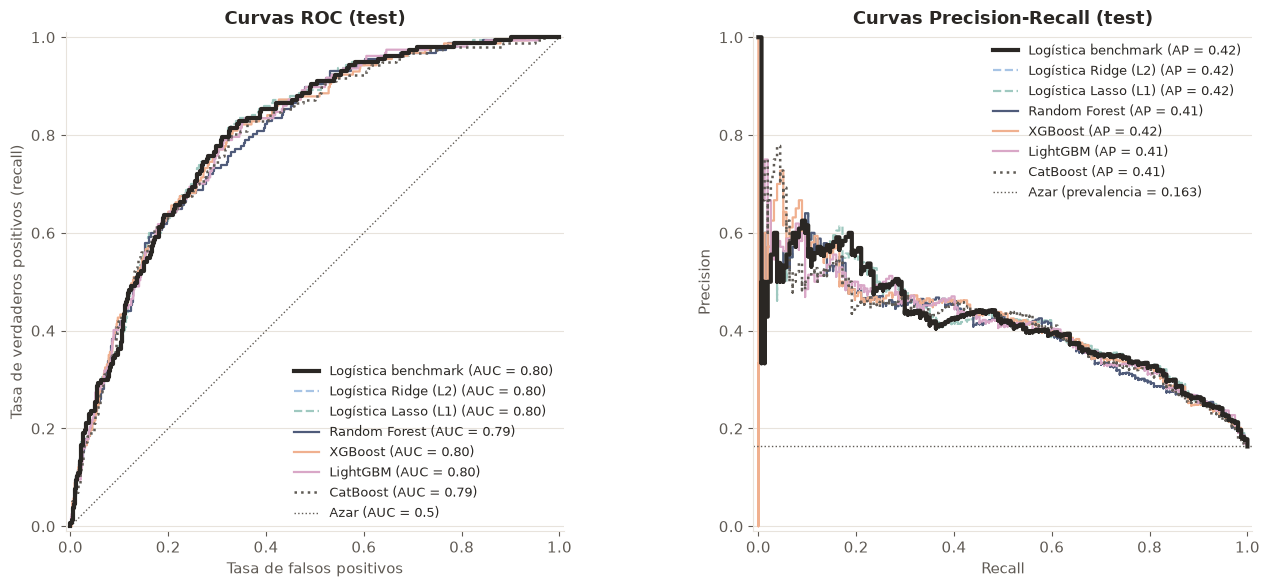

In [16]:
fig = graficar_curvas_roc_pr(pipelines, X_test, y_test)
plt.show()

Las curvas prácticamente se superponen en todo su recorrido, tanto en ROC como en Precision-Recall: ningún modelo domina a la logística benchmark en ninguna zona de umbrales. La curva PR muestra que la precision solo supera 0.5 a costa de un recall muy bajo (< 0.2), y que para recuperar la mayoría de los casos de depresión la precision baja a ~0.3. Es decir, el límite lo pone la información que contienen los 6 predictores y no la flexibilidad del modelo.

**Matrices de Confusión**

Se comparan, con el umbral 0.5, la matriz de confusión de la logística benchmark y la del mejor modelo según la PR-AUC de CV.

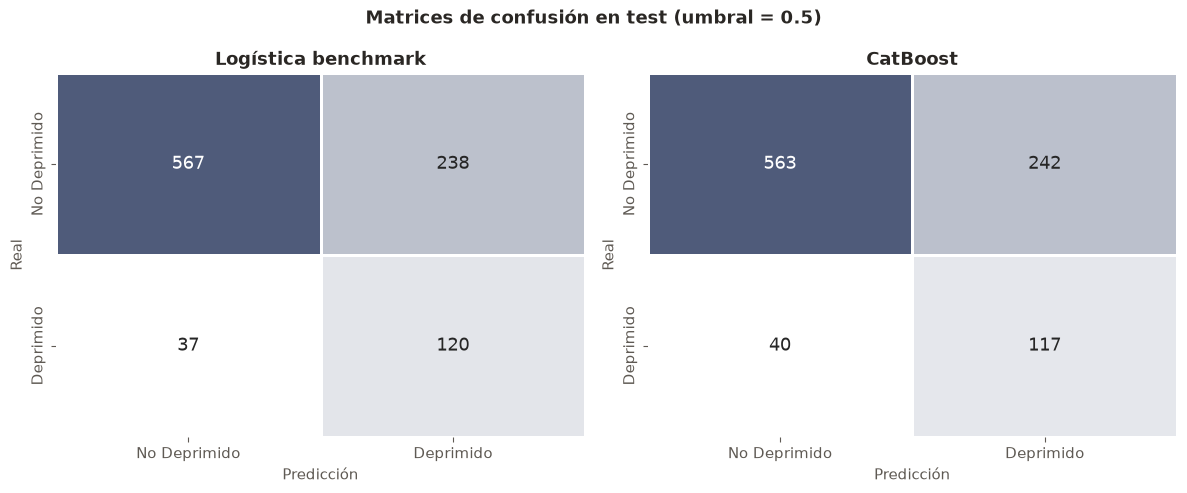

In [17]:
fig = graficar_matrices_confusion(pipelines, clave_mejor, X_test, y_test, umbral=UMBRAL)
plt.show()

Con el umbral 0.5, la logística benchmark identifica 120 de los 157 adolescentes deprimidos del test (recall 0.76) con 238 falsos positivos; CatBoost identifica 117 (recall 0.75) con 242 falsos positivos. Las dos matrices son casi iguales. En ambos casos, los pesos de clase balanceados hacen que el modelo priorice detectar casos positivos (pocos falsos negativos) a costa de muchos falsos positivos: aproximadamente 2 de cada 3 alertas son falsas.

### Persistencia de los Modelos

Se guarda todo en `data/processed/modelado/` (excluido de git por el `.gitignore`):

- `modelos/<clave>.joblib`: el Pipeline completo (preprocesamiento + modelo) reentrenado con todo el train. Al cargarlo recibe un DataFrame con las columnas originales y devuelve `predict_proba` directamente.
- `metadatos.json`: fecha de entrenamiento, SEED, predictores (en orden), target, umbral, modelo de referencia, mejor modelo según PR-AUC de CV, mejores hiperparámetros y versiones de las librerías.
- `metricas_cv.csv` y `metricas_test.csv`: las tablas del benchmarking.
- `split_indices.csv`: `subject_id` y conjunto (`train` | `test`) para poder reconstruir el test.

Los `.joblib` solo se cargan de forma fiable con las mismas versiones de librerías con que se guardaron; por eso están fijadas en `docker/environment.yml` y quedan registradas en los metadatos.

In [18]:
guardar_modelos(pipelines)
guardar_metricas(tabla_cv, tabla_test)
guardar_split(df_train, df_test)
metadatos = guardar_metadatos(clave_mejor,mejores_hiperparametros)

print("Mejor modelo:", metadatos["mejor_modelo_pr_auc_cv"])
print("Versiones:", metadatos["versiones"])

Mejor modelo: catboost
Versiones: {'python': '3.11.16', 'scikit-learn': '1.9.1', 'xgboost': '3.4.2', 'lightgbm': '4.7.0', 'catboost': '1.2.9', 'joblib': '1.6.0'}


**Verificación:** se recarga un modelo desde disco, se reconstruye el test a partir de `split_indices.csv` y se comprueba que las probabilidades coinciden con las del modelo en memoria.

In [19]:
modelo_cargado = cargar_modelo(clave_mejor)

split = pd.read_csv("/workspace/data/processed/modelado/split_indices.csv")
ids_test = split.loc[split["conjunto"] == "test", "subject_id"]
df_test_reconstruido = df[df["subject_id"].isin(ids_test)]

proba_disco = modelo_cargado.predict_proba(df_test_reconstruido[PREDICTORES])[:, 1]
proba_memoria = pipelines[clave_mejor].predict_proba(df_test_reconstruido[PREDICTORES])[:, 1]
print("Mismas predicciones:", np.allclose(proba_disco, proba_memoria))

Mismas predicciones: True


### Conclusiones

- **Modelo ganador:** según la PR-AUC de validación cruzada, el mejor modelo es **CatBoost** (0.395 ± 0.022), que supera a la logística benchmark (0.388 ± 0.015) por solo **+0.007** de PR-AUC. En el test esa ventaja desaparece (0.414 frente a 0.417 del benchmark).
- **Las diferencias no son relevantes:** la distancia entre el mejor y el peor modelo en CV (0.007) es menor que la desviación estándar entre folds de cualquiera de ellos (0.013–0.026), y el ranking cambia entre CV y test. Los modelos de árboles no encuentran no linealidades ni interacciones que la regresión logística no capture ya.
- **Interpretación:** con estos 6 predictores el desempeño tiene un techo de PR-AUC ≈ 0.39–0.42 y ROC-AUC ≈ 0.75–0.80, más del doble que el azar (~0.164) pero lejos de un clasificador clínico preciso. Dado el empate, la **logística benchmark** (o la Lasso, que además descarta `social_jetlag_hours`) es una opción preferible por simplicidad e interpretabilidad; CatBoost queda guardado como el mejor según el criterio definido de antemano.
- **Advertencia sobre el umbral:** todas las métricas de clase (precision, recall, F1, accuracy y las matrices de confusión) usan el umbral por defecto de **0.5, que no está optimizado**. Con pesos de clase balanceados produce un recall alto (~0.75) y una precision baja (~0.33). Elegir el umbral según el objetivo (por ejemplo, un recall mínimo para tamizaje) queda para una siguiente fase, y deberá hacerse con validación cruzada en el train, no con el test.
- Los 7 modelos entrenados, sus métricas, los metadatos y el split quedan guardados en `data/processed/modelado/` y se recuperan con `cargar_modelo(clave)` desde `src/Modelado.py`.